## Claim Verification Results on the Time Split data

In [87]:
MODEL_NAME_MAPPING = {
    'gpt-5.2': 'GPT 5.2',
    'Llama-3.2-3B-Instruct': 'Llama 3.2',
    'gemma-4-31B-it': 'Gemma 4'
}

PARTITION = 'dev'
VERSION = '2026.06.09'
DATASET = 'civicfactnew'

In [88]:
from utils import read_jsonl

train_df = read_jsonl('../data/civicfact-2026.03.03/data.jsonl.gz')
training_documents = set(train_df[train_df.partition.isin({'test', 'dev', 'train'})]['document.pmid'].tolist())

dataset_df = read_jsonl('../data/civicfactnew-2026.06.09/data.jsonl.gz')
print('total civic entries in dataset', dataset_df['civic.id'].nunique())
print('total new submissions', dataset_df[dataset_df.gold_label_name == 'SUPPORTS']['civic.id'].nunique())
print('total new claims', dataset_df[dataset_df.gold_label_name == 'SUPPORTS']['claim.flat'].nunique())

# post filtering on training documents?
dataset_df = dataset_df[~dataset_df['document.pmid'].isin(training_documents)]
print('after filtering on training document overlap')
print('total civic entries in dataset', dataset_df['civic.id'].nunique())
print('total new submissions', dataset_df[dataset_df.gold_label_name == 'SUPPORTS']['civic.id'].nunique())
print('total new claims', dataset_df[dataset_df.gold_label_name == 'SUPPORTS']['claim.flat'].nunique())
dataset_df.head()

total civic entries in dataset 150
total new submissions 122
total new claims 100
after filtering on training document overlap
total civic entries in dataset 134
total new submissions 116
total new claims 95


,auto_accepted,civic.id,claim,claim.flat,corrections,corrections.disease,corrections.evidenceDirection,corrections.evidenceType,corrections.phenotypes,corrections.significance,...,source,source.citationId,source.name,source.pmcId,source.sourceType,status,submittedAt,therapies,therapyInteractionType,variantOrigin
0,True,10339,{'content': {'disease': 'Acute Myeloid Leukemi...,"{\n ""disease"": ""Acute Myeloid Leukemia"",\n ""...",NaN,NaN,NaN,NaN,"[[Acute myeloid leukemia], []]",NaN,...,NaN,26712909,"PubMed: Lewinsohn et al., 2016",PMC4968341,PUBMED,SUBMITTED,2022-05-24T04:00:49Z,[],SUBSTITUTES,RARE_GERMLINE
1,True,10344,"{'content': {'disease': 'Myeloid Neoplasm', 'e...","{\n ""disease"": ""Myeloid Neoplasm"",\n ""eviden...",NaN,NaN,NaN,NaN,"[[Acute myeloid leukemia, Myelodysplasia], []]",NaN,...,NaN,32307695,"PubMed: Qu et al., 2021",PMC9205684,PUBMED,SUBMITTED,2022-05-24T05:14:43Z,[],SUBSTITUTES,SOMATIC
2,True,10346,{'content': {'disease': 'Acute Myeloid Leukemi...,"{\n ""disease"": ""Acute Myeloid Leukemia"",\n ""...",NaN,NaN,NaN,NaN,"[[Acute myeloid leukemia], []]",NaN,...,NaN,33585199,"PubMed: Bannon et al., 2020",PMC7878971,PUBMED,SUBMITTED,2022-05-25T01:08:14Z,[],SUBSTITUTES,SOMATIC
3,NaN,10600,{'content': {'disease': 'Diffuse Midline Gliom...,"{\n ""disease"": ""Diffuse Midline Glioma, H3 K2...",NaN,NaN,NaN,"[DIAGNOSTIC, ONCOGENIC]","[[Childhood onset, Juvenile onset, Young adult...","[positive, oncogenicity]",...,NaN,26399631,"PubMed: Castel et al., 2015",PMC4654747,PUBMED,SUBMITTED,2022-07-21T20:51:08Z,[],SUBSTITUTES,SOMATIC
5,NaN,11111,"{'content': {'disease': 'Follicular Lymphoma',...","{\n ""disease"": ""Follicular Lymphoma"",\n ""evi...",NaN,NaN,NaN,"[DIAGNOSTIC, ONCOGENIC]",NaN,"[negative, oncogenicity]",...,NaN,24052547,"PubMed: Bödör et al., 2013",PMC3814734,PUBMED,ACCEPTED,2023-02-12T23:30:01Z,[],SUBSTITUTES,SOMATIC


## What did manual review tell us about retrieval?

In [ ]:
CLAIM_DOC_LABEL_NAMES = [
    'added_to_hypothesis',
    'bad_accepted_revision',
    'bad_linked_term',
    'civic_entry_ok',
    'exp_revision_approx_eq_claim',
    'major_revision',
    'need_second_opinion',
    'new_label_nei',
    'new_label_revisions',
    'new_label_supports',
    'not_in_main_text',
    'repurposed_eid',
    'requires_image',
    'requires_supplement',
    'retrieval_failed_medcpt',
    'retrieval_failed_qwen',
    'retrieval_ok_medcpt',
    'retrieval_ok_qwen',
    'wrong_or_bad_source',
    'exclude_from_analysis'
]

manual_df = read_jsonl('../../manual_reviews/data/doccano/project_104/output.jsonl.gz')

for field in manual_df.meta.tolist()[0].keys():
    if field not in manual_df.columns:
        manual_df[field] = manual_df.meta.str[field]

manual_df['correct'] = manual_df.gold_label_name == manual_df.predicted_label_name
# add civic.id to list
manual_df = manual_df.merge(dataset_df[['claim.flat', 'document.pmid', 'civic.id']].drop_duplicates(), validate='many_to_one')

# if an EID was both submitted and revised, only keep the submitted claim
eid_df = manual_df[['civic.id', 'gold_label_name']].drop_duplicates().sort_values(['gold_label_name']).drop_duplicates(['civic.id'], keep='last')
manual_df = manual_df.merge(eid_df)
print('civic entries for which we have reviewed retrieval results?', manual_df['civic.id'].nunique())
print('civic entries for which we have reviewed retrieval results (new submissions only)?', manual_df[manual_df.gold_label_name == 'SUPPORTS']['civic.id'].nunique())





claim_doc_labels = {}

for _, row in manual_df.iterrows():
    key = (row['claim.flat'], row['document.pmid'])
    for annotation in row.annotations:
        if annotation['labelname'] in CLAIM_DOC_LABEL_NAMES or annotation['labelname'].startswith('retrieval'):
            claim_doc_labels.setdefault(key, set()).add(annotation['labelname'])

manual_df['claim_labels'] = manual_df.apply(lambda row: claim_doc_labels.get((row['claim.flat'], row['document.pmid']), set()), axis=1)
manual_df['instance_labels'] = manual_df.apply(lambda row: {a['labelname'] for a in row['annotations']} | row['claim_labels'], axis=1)
manual_df['instance_id'] = manual_df['claim.flat'] + ' ' + manual_df['evidence.flat'] + manual_df['document.pmid']
manual_df.head()

civic entries for which we have reviewed retrieval results? 68
civic entries for which we have reviewed retrieval results (new submissions only)? 61


,annotation_approver,annotations,assignments,comment_count,comments,filename,id,is_confirmed,is_confirmed_by,meta,...,generated_text,gold_label_name,predicted_label_name,retrieval,revised_claim.flat,correct,civic.id,claim_labels,instance_labels,instance_id
0,NaN,"[{'created_at': '2026-06-10T20:39:56.754390Z',...",[],0,[],http://doccano.bcgsc.ca/media/czxfVA54qMnsKzqp...,124286,True,[admin],"{'claim.flat': '{ ""disease"": ""Urinary Bladde...",...,"REVISIONS\n\n{\n ""disease"": ""Urinary Bladder ...",REVISIONS,REVISIONS,qwen-mongoose,"{\n ""evidenceDirection"": ""SUPPORTS"",\n ""evid...",True,8811,"{repurposed_eid, new_label_nei}","{repurposed_eid, new_label_nei, main}","{\n ""disease"": ""Urinary Bladder Cancer"",\n ""..."
1,NaN,"[{'created_at': '2026-06-10T20:44:21.040103Z',...",[],0,[],http://doccano.bcgsc.ca/media/czxfVA54qMnsKzqp...,124287,True,[admin],"{'claim.flat': '{ ""disease"": ""Urinary Bladde...",...,label: SUPPORTS\n\nrevised claim: none\n\nexpl...,REVISIONS,SUPPORTS,qwen-mongoose,"{\n ""evidenceDirection"": ""SUPPORTS"",\n ""evid...",False,8811,"{repurposed_eid, new_label_nei}","{repurposed_eid, new_label_nei}","{\n ""disease"": ""Urinary Bladder Cancer"",\n ""..."
2,NaN,"[{'created_at': '2026-06-10T20:44:29.593758Z',...",[],0,[],http://doccano.bcgsc.ca/media/czxfVA54qMnsKzqp...,124288,True,[admin],"{'claim.flat': '{ ""disease"": ""Urinary Bladde...",...,"label: REVISIONS\n\nrevised claim:\n{\n ""dise...",REVISIONS,REVISIONS,medcpt-goat,"{\n ""evidenceDirection"": ""SUPPORTS"",\n ""evid...",True,8811,"{repurposed_eid, new_label_nei}","{repurposed_eid, new_label_nei}","{\n ""disease"": ""Urinary Bladder Cancer"",\n ""..."
3,NaN,"[{'created_at': '2026-06-10T20:45:05.698467Z',...",[],0,[],http://doccano.bcgsc.ca/media/czxfVA54qMnsKzqp...,124289,True,[admin],"{'claim.flat': '{ ""disease"": ""Urinary Bladde...",...,"REVISIONS\n\n```json\n{\n ""disease"": ""Urinary...",REVISIONS,REVISIONS,qwen-mongoose,"{\n ""evidenceDirection"": ""SUPPORTS"",\n ""evid...",True,8811,"{repurposed_eid, new_label_nei}","{repurposed_eid, new_label_nei}","{\n ""disease"": ""Urinary Bladder Cancer"",\n ""..."
4,NaN,"[{'created_at': '2026-06-10T20:45:33.891144Z',...",[],0,[],http://doccano.bcgsc.ca/media/czxfVA54qMnsKzqp...,124290,True,[admin],"{'claim.flat': '{ ""disease"": ""Urinary Bladde...",...,"<assistant_response id=""target"">\nREVISIONS\n\...",REVISIONS,REVISIONS,medcpt-goat,"{\n ""evidenceDirection"": ""SUPPORTS"",\n ""evid...",True,8811,"{repurposed_eid, new_label_nei}","{repurposed_eid, new_label_nei}","{\n ""disease"": ""Urinary Bladder Cancer"",\n ""..."


In [90]:
def get_new_label(row):
    labels = set()
    current_tags = row['claim_labels']

    if'exclude_from_analysis' in current_tags:
        return ''
    for label in ['requires_image', 'requires_supplement', 'not_in_main_text']:
        if label in current_tags:
            return 'NEI'

    for label in ['nei', 'supports', 'revisions']:
        if 'new_label_' + label in current_tags:
            labels.add(label.upper())
    # for ann in row['annotations']:
    #     if ann['labelname'].startswith('new_label_'):
    #         labels.add(ann['labelname'][len('new_label_'):].upper())
    if not labels:
        labels = {row['gold_label_name']}
    elif len(labels) > 1:
        raise NotImplementedError(f'not sure what to do with multiple labels: {labels}')
    return list(labels)[0]


def classify_level(row):
    if 'exclude_from_analysis' in row['claim_labels']:
        return 'exclude'
    for label in ['requires_image', 'requires_supplement', 'not_in_main_text']:
        if label in row['claim_labels']:
            return 'not_in_main_text'
    if row['new_gold_label_name'] == 'SUPPORTS':
            return 'none'
    if 'major_revision' in row['claim_labels']:
        return 'major'
    if 'REVISIONS' == row['new_gold_label_name']:
        return 'minor'
    if row['new_gold_label_name'] == 'NEI':
        return 'NEI'
    print('classifying level failed', row['claim_labels'], row['new_gold_label_name'])
    return 'other'


manual_df['new_gold_label_name'] = manual_df.apply(get_new_label, axis=1)
manual_df['flag_level'] = manual_df.apply(classify_level, axis=1)

manual_df.flag_level.value_counts(dropna=False)

flag_level
none                144
not_in_main_text    144
major                54
minor                42
NEI                  12
exclude              12
Name: count, dtype: int64

In [91]:
## check each civic id only has 1 correct label
temp_df = manual_df.groupby(['civic.id']).agg({'new_gold_label_name': 'nunique', 'gold_label_name': 'nunique'}).reset_index()
temp_df[temp_df.new_gold_label_name > 1]

,civic.id,new_gold_label_name,gold_label_name


In [92]:
def classify_retrieval(row):
    ret_type = row['retrieval'].split('-')[0]
    ret_ok_label = f'retrieval_ok_{ret_type}'
    ret_fail_label = f'retrieval_failed_{ret_type}'

    labels = row['instance_labels']

    if {'requires_supplement', 'requires_image', 'not_in_main_text', 'repurposed_eid'} & labels:
        return 'NEI'

    if ret_ok_label in labels and ret_fail_label in labels:
        return 'MIXED'
    elif ret_ok_label in labels:
        return 'OK'
    elif ret_fail_label in labels:
        return 'FAILED'
    elif row['new_gold_label_name'] == 'NEI':
        return 'NEI'
    print(row['instance_labels'], row['comments'])
    return None


ret_df = manual_df.copy()
ret_df = ret_df.sort_values(['gold_label_name'])
ret_df = ret_df.drop_duplicates(['civic.id', 'retrieval'], keep='last')  # do not look at revisions on newly submitted items only revisions on existing

print('all submissions reviewed', ret_df['civic.id'].nunique())
print('new submissions reviewed', ret_df[ret_df.gold_label_name == 'SUPPORTS']['civic.id'].nunique())
print('all documents reviewed', ret_df['document.pmid'].nunique())

ret_df['id'] = ret_df['claim.flat'] + ret_df['document.pmid']
ret_df['retrieval_status'] = ret_df.apply(classify_retrieval, axis=1)

ret_df.groupby(['retrieval', 'retrieval_status'], dropna=False).agg({'id': 'nunique', 'document.pmid': 'unique', 'civic.id': 'nunique'})

all submissions reviewed 68
new submissions reviewed 61
all documents reviewed 40
{'exclude_from_analysis', 'major_revision', 'new_label_nei', 'bad_accepted_revision', 'new_label_revisions'} []
{'exclude_from_analysis', 'major_revision', 'new_label_nei', 'bad_accepted_revision', 'new_label_revisions'} []
{'exclude_from_analysis', 'main', 'bad_linked_term'} []
{'exclude_from_analysis', 'bad_linked_term'} []


id  \
retrieval     retrieval_status       
medcpt-goat   FAILED             3   
              NEI               26   
              OK                37   
              NaN                2   
qwen-mongoose FAILED             2   
              MIXED              1   
              NEI               26   
              OK                37   
              NaN                2   

                                                                    document.pmid  \
retrieval     retrieval_status                                                      
medcpt-goat   FAILED                               [32307695, 41325571, 33707599]   
              NEI               [26399631, 23153540, 17384684, 33585199, 41361...   
              OK                [22918081, 40764304, 40706052, 37900238, 37479...   
              NaN                                            [31821784, 30630978]   
qwen-mongoose FAILED                                         [32307695, 29670690]   
              MIXED                                                    [20815032]   
              NEI               [23153540, 26399631, 17384684, 33585199, 41361...   
              OK                [22918081, 40764304, 41325571, 37900238, 37479...   
              NaN                                            [31821784, 30630978]   

                                civic.id  
retrieval     retrieval_status            
medcpt-goat   FAILED                   3  
              NEI                     26  
              OK                      37  
              NaN                      2  
qwen-mongoose FAILED                   2  
              MIXED                    1  
              NEI                     26  
              OK                      37  
              NaN                      2

## Now how did each model do for claim-verification?

In [93]:
# first load the document chunks
doc_df = read_jsonl(f'../data/civicfact-{VERSION}/document_chunks.jsonl.gz')
ft_docs = set(doc_df[doc_df['document.content_source'] != 'pubmed']['document.pmid'].unique())
doc_df['document.pmid'] = doc_df['document.pmid'].astype(str)
doc_df.head()

,acronyms,chunk.end,chunk.id,chunk.overlap,chunk.size,chunk.start,chunk.text,document.content_source,document.length,document.pmid,document.total_chunks,license,partition,passages,pubtator
0,"[{'defn': 'non-small cell lung cancer', 'name'...",1000,26870817:0-1000,100,1000,0,P-glycoprotein Mediates Ceritinib Resistance i...,pmc,44838,26870817,50,CC BY-NC-ND,train,"[{'passage.end': 113, 'passage.section': 'titl...","[{'match.end': 14.0, 'match.start': 0.0, 'matc..."
1,"[{'defn': 'non-small cell lung cancer', 'name'...",1900,26870817:900-1900,100,1000,900,p/ABCB1) overexpression as a ceritinib resista...,pmc,44838,26870817,50,CC BY-NC-ND,train,"[{'passage.end': 1586, 'passage.section': 'abs...","[{'match.end': 938.0, 'match.start': 929.0, 'm..."
2,"[{'defn': 'non-small cell lung cancer', 'name'...",2800,26870817:1800-2800,100,1000,1800,t not to alectinib and PF-06463922.\n*\nCeriti...,pmc,44838,26870817,50,CC BY-NC-ND,train,"[{'passage.end': 1944, 'passage.section': 'abs...","[{'match.end': 1847.0, 'match.start': 1838.0, ..."
3,"[{'defn': 'non-small cell lung cancer', 'name'...",3700,26870817:2700-3700,100,1000,2700,"stance, suggesting that P-gp expression could ...",pmc,44838,26870817,50,CC BY-NC-ND,train,"[{'passage.end': 2810, 'passage.section': 'abs...","[{'match.end': 2855.0, 'match.start': 2829.0, ..."
4,"[{'defn': 'non-small cell lung cancer', 'name'...",4600,26870817:3600-4600,100,1000,3600,ORR; 65% (113/173) vs 20% (34/174) in the seco...,pmc,44838,26870817,50,CC BY-NC-ND,train,"[{'passage.end': 4436, 'passage.section': 'art...","[{'match.end': 4412.0, 'match.start': 4398.0, ..."


In [94]:
# load the results
import subprocess

inputs = subprocess.check_output(["find",  "../results/claim_verification",  "-regex",  '.*evaluations.*civicfactnew.*/.*all.processed.jsonl.gz']).decode().split('\n')

inputs = [f.strip() for f in inputs if f.strip() and '_f0.' not in f]
print(f'found {len(inputs)} matching input files')
print(inputs)

df = read_jsonl(*inputs, add_filename=True, add_filepath_metadata=True)

ft_model ='meta-llama__Llama-3.2-3B-Instruct'
df['ft'] = df['filepath.train_dataset'].fillna('') != ''

# df = df[((df['filepath.ret_model'] == 'qwen-mongoose') & (df['filepath.model_dir'] != ft_model)) | ((df['filepath.model_dir'] == ft_model) & (df['filepath.ret_model'] == 'medcpt-goat'))]

df = df[(df['filepath.ret_model'] == 'qwen-mongoose')]

df = df[(df.ft == True) | (df['filepath.model_dir'] != ft_model)]

print(df[['filepath.model_dir', 'filepath.ret_model']].value_counts())
check_df = df.groupby(['filepath.model_dir', 'ft']).agg({'filename':'nunique'}).reset_index()
print(check_df)
assert (check_df.filename == 1).all()
df['correct'] = df.gold_label_name == df.predicted_label_name
df['document.pmid'] = df['document.pmid'].astype(str)
df['id'] = df['claim.flat'] + ':' + df['document.pmid'].astype(str) + df['evidence.flat']

df = df.merge(doc_df[['document.pmid', 'document.content_source']].drop_duplicates())
print(df['document.content_source'].value_counts(dropna=False))
df = df[df['document.content_source'] != 'pubmed']
df = df.rename(columns={"freq": "dataset_size"})


for col in [
    'filepath.chat_template',
    'filepath.data_version',
    'filepath.embedding_mode',
    'filepath.eval_dataset',
    'filepath.generation_config',
    'filepath.pairing_mode',
    'filepath.prompt_template',
    'filepath.ret_model',
    'filepath.subsample_filter',
    'filepath.train_data_version',
    'filepath.train_prompt_template',
]:
    if col not in df:
        df[col] = None

df = df[
    # (df['filepath.prompt_template'].fillna('none').isin({'none', 'labelfirst', 'verboselimit100'}))
    (df['filepath.data_version'].isin({VERSION}))
    & (~df['filepath.train_dataset'].isin({'civicfactx5000g8'}))
    & (df['filepath.subsample_fraction'].astype(float).fillna(1) == 1)
]
df['document.pmid'] = df['document.pmid'].astype(str)

df = df.merge(doc_df[['document.pmid', 'document.content_source']].drop_duplicates())

print(df.shape)
df['subset'] = df['filepath.subsample_filter'].fillna('all')

# filter on model best param picks
# df = df[(~df.model.isin({'Mixtral', 'Llama 3.1'})) | (df['filepath.prompt_template'] == 'verifyevidence')]
# df = df[(~df.model.isin({'Mixtral', 'Llama 3.1', 'Llama 4-Scout'})) | (df['filepath.examples'].astype(float) == 30)]

print(df.filename.nunique(), 'files after filtering')


df['retrieval'] =  df['filepath.ret_model']
df.loc[df.retrieval == 'random42', 'retrieval'] = 'Random'
df.loc[df.retrieval == 'head-oracle', 'retrieval'] = 'Oracle'
df.loc[~df['filepath.eval_dataset'].str.contains('pairs'), 'retrieval'] = 'Human'
df.loc[df['filepath.eval_dataset'] == 'civicfactft', 'retrieval'] = 'Full-Text'

if df[df.model.str.contains('(FT)', regex=False)].model.nunique() == 1:
    print(df.model.unique())
    df['model'] = df['model'].str.replace(r'\[\dB\] \(FT\).*', '(FT)', regex=True)



df.loc[df['document.content_source'] != 'pubmed','document.content_source' ] = 'PMC'
df["model"] = df['filepath.model_dir'].str.split("__").str[-1].apply(lambda x: MODEL_NAME_MAPPING.get(x))
df = df[~df.model.isna()]
df.loc[~df['filepath.train_data_version'].isna(), 'model'] += ' (FT)'

print('total claim/document/retrieval pairs', df['id'].nunique())
print('new submission pairs', df[df.gold_label_name == 'SUPPORTS']['id'].nunique())

data_df = df

previous_count = df[['model', 'filepath.train_data_version', 'filepath.data_version', 'model', 'filepath.eval_dataset']].drop_duplicates().shape[0]
df.head()

found 12 matching input files
['../results/claim_verification/fine-tuning/config-16/completion/civicfactchunk-2026.03.03/chat-default/prompts.verifyevidencetrain.0-shot.train.jsonl/meta-llama__Llama-3.2-3B-Instruct/evaluations/civicfactnewpairs-medcpt-goat-L5000-qt0-2026.06.09/chat-default/gen-5/prompts.verifyevidencetrain.0-shot.all.processed.jsonl.gz', '../results/claim_verification/fine-tuning/config-16/completion/civicfactchunk-2026.03.03/chat-default/prompts.verifyevidencetrain.0-shot.train.jsonl/meta-llama__Llama-3.2-3B-Instruct/evaluations/civicfactnewpairs-qwen-mongoose-L5000-qt0-2026.06.09/chat-default/gen-5/prompts.verifyevidencetrain.0-shot.all.processed.jsonl.gz', '../results/claim_verification/evaluations/meta-llama__Meta-Llama-3.1-70B-Instruct/civicfactnewpairs-medcpt-goat-L5000-qt0-2026.06.09/chat-default/gen-12/prompts.verifyevidence.15-shot.all.processed.jsonl.gz', '../results/claim_verification/evaluations/meta-llama__Llama-3.2-3B-Instruct/civicfactnewpairs-qwen-mongo

,assignment.round,auto_accepted,chat,chat_template,chunks,civic.id,claim,claim.flat,corrections,corrections.disease,...,request.reasoning_effort,request.temperature,response,ft,correct,document.content_source,filepath.embedding_mode,filepath.pairing_mode,subset,retrieval
0,1,1.0,"[{'content': '<claim id=""target""> { ""disease...",llama-3-chat,"[{'chunk.end': 1000, 'chunk.id': '32307695:0-1...",10344,"{'content': {'disease': 'Myeloid Neoplasm', 'e...","{\n ""disease"": ""Myeloid Neoplasm"",\n ""eviden...",NaN,NaN,...,NaN,NaN,NaN,True,True,PMC,None,None,all,qwen-mongoose
1,1,1.0,"[{'content': '<claim id=""target""> { ""disease...",llama-3-chat,"[{'chunk.end': 4600, 'chunk.id': '33585199:360...",10346,{'content': {'disease': 'Acute Myeloid Leukemi...,"{\n ""disease"": ""Acute Myeloid Leukemia"",\n ""...",NaN,NaN,...,NaN,NaN,NaN,True,True,PMC,None,None,all,qwen-mongoose
2,1,NaN,"[{'content': '<claim id=""target""> { ""disease...",llama-3-chat,"[{'chunk.end': 1000, 'chunk.id': '26399631:0-1...",10600,{'content': {'disease': 'Diffuse Midline Gliom...,"{\n ""disease"": ""Diffuse Midline Glioma, H3 K2...",NaN,NaN,...,NaN,NaN,NaN,True,False,PMC,None,None,all,qwen-mongoose
3,1,NaN,"[{'content': '<claim id=""target""> { ""disease...",llama-3-chat,"[{'chunk.end': 1000, 'chunk.id': '19193436:0-1...",11158,{'content': {'disease': 'Systemic Mastocytosis...,"{\n ""disease"": ""Systemic Mastocytosis"",\n ""e...",NaN,NaN,...,NaN,NaN,NaN,True,False,PMC,None,None,all,qwen-mongoose
4,1,NaN,"[{'content': '<claim id=""target""> { ""disease...",llama-3-chat,"[{'chunk.end': 1000, 'chunk.id': '19193436:0-1...",11160,{'content': {'disease': 'Systemic Mastocytosis...,"{\n ""disease"": ""Systemic Mastocytosis"",\n ""e...",NaN,NaN,...,NaN,NaN,NaN,True,False,PMC,None,None,all,qwen-mongoose


In [95]:
df = data_df[['model', 'filepath.train_dataset', 'claim.flat', 'document.pmid', 'predicted_label_name', 'retrieval', 'filename']].merge(ret_df[['retrieval', 'retrieval_status', 'new_gold_label_name', 'claim.flat', 'document.pmid', 'civic.id']].drop_duplicates())
df = df[~df.retrieval_status.isna()]
print(df.model.unique())
print(len(df))
print(df['civic.id'].nunique())
print(df[['retrieval_status', 'new_gold_label_name']].value_counts(dropna=False))
df.loc[df['retrieval_status'] != 'OK', 'new_gold_label_name'] = 'NEI'
def check_correct(row):
    return row['predicted_label_name'] in row['new_gold_label_name'].split(';')

df['correct'] = df.apply(check_correct, axis=1)
df = df.drop_duplicates(['filename', 'claim.flat', 'document.pmid', 'civic.id'])
print(df.model.unique())
df['freq'] = 1
df = df.groupby(['model', 'filepath.train_dataset',  'filename'], dropna=False).agg({'civic.id': 'nunique', 'claim.flat': 'nunique', 'correct': 'sum', 'freq': 'sum', 'document.pmid': 'nunique'}).reset_index()
print(df.model.unique())
df['accuracy'] = df.correct/ df.freq
df.sort_values(['accuracy'])

<ArrowStringArray>
['Llama 3.2 (FT)', 'Gemma 4', 'GPT 5.2']
Length: 3, dtype: str
198
66
retrieval_status  new_gold_label_name
NEI               NEI                    78
OK                SUPPORTS               66
                  REVISIONS              45
FAILED            SUPPORTS                3
MIXED             SUPPORTS                3
FAILED            REVISIONS               3
Name: count, dtype: int64
<ArrowStringArray>
['Llama 3.2 (FT)', 'Gemma 4', 'GPT 5.2']
Length: 3, dtype: str
<ArrowStringArray>
['GPT 5.2', 'Gemma 4', 'Llama 3.2 (FT)']
Length: 3, dtype: str


,model,filepath.train_dataset,filename,civic.id,claim.flat,correct,freq,document.pmid,accuracy
2,Llama 3.2 (FT),civicfactchunk,../results/claim_verification/fine-tuning/conf...,66,65,17,66,38,0.257576
0,GPT 5.2,NaN,../results/claim_verification/api/evaluations/...,66,65,44,66,38,0.666667
1,Gemma 4,NaN,../results/claim_verification/evaluations/goog...,66,65,48,66,38,0.727273


## What about flagging accuracy?

In [96]:
def agg_flag_levels(levels):
    if 'exclude' in levels:
        return 'exclude'
    if 'not_in_main_text' in levels:
        return 'not_in_main_text'
    levels = set(levels)
    if 'major' in levels:
        return 'major'
    if len(levels) > 1 and len(levels - {'none'}):
        levels -= {'none'}
    if len(levels) > 1 and len(levels - {'other'}):
        levels -= {'other'}
    if 'NEI' in levels:
        return 'NEI'
    return ' / '.join(sorted(levels))


flag_df = manual_df.groupby(['civic.id', 'new_gold_label_name']).agg({'flag_level': agg_flag_levels}).reset_index()
dup = flag_df[['civic.id']].value_counts(dropna=False).reset_index(name='freq')
print(dup[dup['freq'] > 1])
print(manual_df[manual_df['civic.id'] == '12933'][['civic.id', 'claim_labels', 'instance_labels', 'flag_level', 'new_gold_label_name']])
flag_df.groupby(['new_gold_label_name', 'flag_level']).agg({'civic.id': 'nunique'})

Empty DataFrame
Columns: [civic.id, freq]
Index: []
    civic.id                              claim_labels  \
222    12933  {retrieval_ok_medcpt, retrieval_ok_qwen}   
223    12933  {retrieval_ok_medcpt, retrieval_ok_qwen}   
224    12933  {retrieval_ok_medcpt, retrieval_ok_qwen}   
225    12933  {retrieval_ok_medcpt, retrieval_ok_qwen}   
226    12933  {retrieval_ok_medcpt, retrieval_ok_qwen}   
227    12933  {retrieval_ok_medcpt, retrieval_ok_qwen}   

                                       instance_labels flag_level  \
222  {retrieval_ok_medcpt, model_revision_incorrect...       none   
223  {retrieval_ok_medcpt, no_actual_revision, retr...       none   
224  {retrieval_ok_medcpt, model_revision_incorrect...       none   
225  {retrieval_ok_medcpt, model_revision_incorrect...       none   
226           {retrieval_ok_medcpt, retrieval_ok_qwen}       none   
227  {retrieval_ok_medcpt, model_revision_incorrect...       none   

    new_gold_label_name  
222            SUPPORTS  
223  

civic.id
new_gold_label_name flag_level                
                    exclude                  2
NEI                 NEI                      2
                    not_in_main_text        24
REVISIONS           major                    9
                    minor                    7
SUPPORTS            none                    24

<ArrowStringArray>
['Llama 3.2 (FT)', 'Gemma 4', 'GPT 5.2']
Length: 3, dtype: str
<ArrowStringArray>
['Llama 3.2 (FT)', 'Gemma 4', 'GPT 5.2']
Length: 3, dtype: str
198
66
retrieval_status  new_gold_label_name
NEI               NEI                    78
OK                SUPPORTS               66
                  REVISIONS              45
FAILED            SUPPORTS                3
MIXED             SUPPORTS                3
FAILED            REVISIONS               3
Name: count, dtype: int64


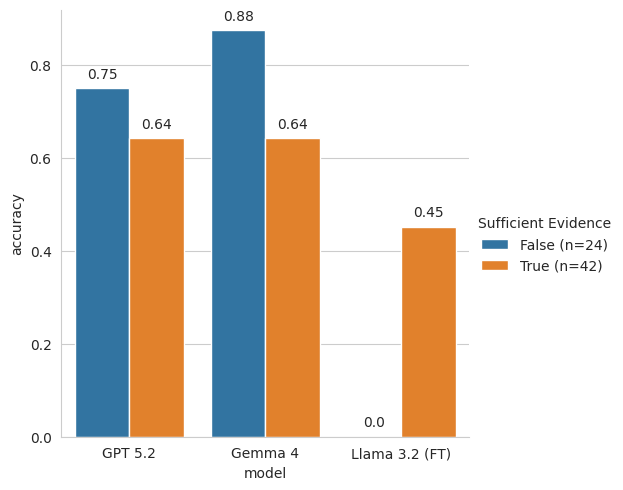

In [97]:
import seaborn as sns
from utils.fig import add_bar_labels

df = data_df[['model', 'filepath.train_dataset', 'claim.flat', 'document.pmid', 'predicted_label_name', 'retrieval', 'filename']].merge(ret_df[['retrieval', 'retrieval_status', 'new_gold_label_name', 'claim.flat', 'document.pmid', 'civic.id']].drop_duplicates()).merge(flag_df)
print(df.model.unique())
df = df[~df.retrieval_status.isna()]
print(df.model.unique())
print(len(df))
print(df['civic.id'].nunique())
print(df[['retrieval_status', 'new_gold_label_name']].value_counts(dropna=False))

def check_correct(row):
    if row['predicted_label_name'] == row['new_gold_label_name']:
        return 1
    return 0



df['correct'] = df.apply(check_correct, axis=1)
df = df.drop_duplicates(['filename', 'claim.flat', 'document.pmid', 'civic.id'])
df['Sufficient Evidence'] = df['flag_level'] != 'not_in_main_text'
df['freq'] = 1
df = df.groupby(['model', 'filepath.train_dataset',  'filename', 'Sufficient Evidence'], dropna=False).agg({'civic.id': 'nunique', 'claim.flat': 'nunique', 'correct': 'sum', 'freq': 'sum', 'document.pmid': 'nunique'}).reset_index()
df['accuracy'] = df.correct/ df.freq



sns.set_style('whitegrid')

# df['Revision Level'] = df.flag_level + ' (n=' + df['civic.id'].astype(str) +')'
df['Sufficient Evidence'] = df['Sufficient Evidence'].astype(str) + ' (n=' + df['civic.id'].astype(str) +')'

fig= sns.catplot(df, y='accuracy', x='model', hue='Sufficient Evidence', kind='bar')


add_bar_labels(fig, fmt=lambda x: round(x, 2), padding=5)


<ArrowStringArray>
['Llama 3.2 (FT)', 'Gemma 4', 'GPT 5.2']
Length: 3, dtype: str
<ArrowStringArray>
['Llama 3.2 (FT)', 'Gemma 4', 'GPT 5.2']
Length: 3, dtype: str
198
66
retrieval_status  new_gold_label_name
NEI               NEI                    78
OK                SUPPORTS               66
                  REVISIONS              45
FAILED            SUPPORTS                3
MIXED             SUPPORTS                3
FAILED            REVISIONS               3
Name: count, dtype: int64


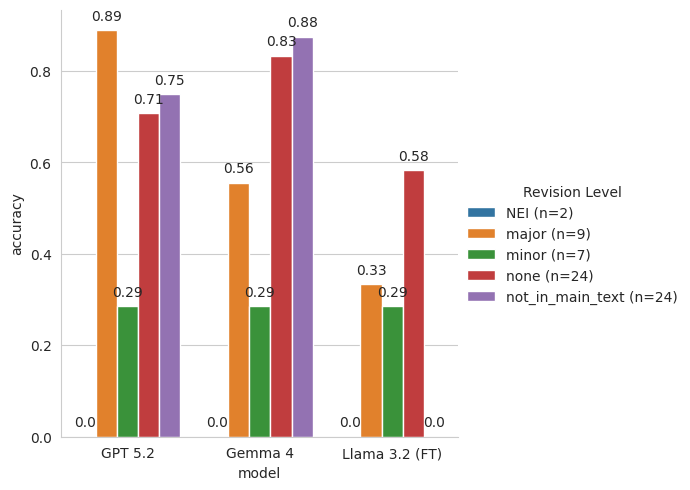

In [100]:
f = data_df[['model', 'filepath.train_dataset', 'claim.flat', 'document.pmid', 'predicted_label_name', 'retrieval', 'filename']].merge(ret_df[['retrieval', 'retrieval_status', 'new_gold_label_name', 'claim.flat', 'document.pmid', 'civic.id']].drop_duplicates()).merge(flag_df)
print(df.model.unique())
df = df[~df.retrieval_status.isna()]
print(df.model.unique())
print(len(df))
print(df['civic.id'].nunique())
print(df[['retrieval_status', 'new_gold_label_name']].value_counts(dropna=False))

def check_correct(row):
    if row['predicted_label_name'] == row['new_gold_label_name']:
        return 1
    return 0



df['correct'] = df.apply(check_correct, axis=1)
df = df.drop_duplicates(['filename', 'claim.flat', 'document.pmid', 'civic.id'])
df['Sufficient Evidence'] = df['flag_level'] != 'not_in_main_text'
df['freq'] = 1
df = df.groupby(['model', 'filepath.train_dataset',  'filename', 'flag_level'], dropna=False).agg({'civic.id': 'nunique', 'claim.flat': 'nunique', 'correct': 'sum', 'freq': 'sum', 'document.pmid': 'nunique'}).reset_index()
df['accuracy'] = df.correct/ df.freq



sns.set_style('whitegrid')

df['Revision Level'] = df.flag_level + ' (n=' + df['civic.id'].astype(str) +')'
# df['Sufficient Evidence'] = df['Sufficient Evidence'].astype(str) + ' (n=' + df['civic.id'].astype(str) +')'

fig= sns.catplot(df, y='accuracy', x='model', hue='Revision Level', kind='bar')


add_bar_labels(fig, fmt=lambda x: round(x, 2), padding=5)

In [98]:
import pandas as pd

df = data_df[['model', 'filepath.train_dataset', 'claim.flat', 'document.pmid', 'predicted_label_name', 'retrieval', 'filename', 'gold_label_name']].merge(ret_df[['retrieval', 'retrieval_status', 'new_gold_label_name', 'claim.flat', 'document.pmid', 'civic.id']].drop_duplicates()).merge(flag_df)
print(df.model.unique())
df = df[~df.retrieval_status.isna()]
print(df.model.unique())
print(len(df))
print(df['civic.id'].nunique())
print(df[['retrieval_status', 'new_gold_label_name']].value_counts(dropna=False))



pd.pivot_table(
    df,
    values='civic.id',
    columns=['predicted_label_name'],
    index=['model','flag_level', 'new_gold_label_name'],
    aggfunc='nunique'
)


<ArrowStringArray>
['Llama 3.2 (FT)', 'Gemma 4', 'GPT 5.2']
Length: 3, dtype: str
<ArrowStringArray>
['Llama 3.2 (FT)', 'Gemma 4', 'GPT 5.2']
Length: 3, dtype: str
198
66
retrieval_status  new_gold_label_name
NEI               NEI                    78
OK                SUPPORTS               66
                  REVISIONS              45
FAILED            SUPPORTS                3
MIXED             SUPPORTS                3
FAILED            REVISIONS               3
Name: count, dtype: int64


predicted_label_name                                  NEI  REVISIONS  SUPPORTS
model          flag_level       new_gold_label_name                           
GPT 5.2        NEI              NEI                   NaN        2.0       NaN
               major            REVISIONS             NaN        8.0       1.0
               minor            REVISIONS             NaN        2.0       5.0
               none             SUPPORTS              1.0        6.0      17.0
               not_in_main_text NEI                  18.0        6.0       NaN
Gemma 4        NEI              NEI                   NaN        2.0       NaN
               major            REVISIONS             NaN        5.0       4.0
               minor            REVISIONS             NaN        2.0       5.0
               none             SUPPORTS              1.0        3.0      20.0
               not_in_main_text NEI                  21.0        3.0       NaN
Llama 3.2 (FT) NEI              NEI                   NaN        1.0       1.0
               major            REVISIONS             NaN        3.0       6.0
               minor            REVISIONS             NaN        2.0       5.0
               none             SUPPORTS              NaN       10.0      14.0
               not_in_main_text NEI                   NaN        6.0      18.0

In [99]:
for _, row in df[(df.model.str.contains("FT")) & (df.new_gold_label_name != df.predicted_label_name)].groupby(['model', 'flag_level', 'gold_label_name', 'new_gold_label_name', 'predicted_label_name']).agg({'document.pmid': 'unique'}).reset_index().iterrows():
    print(dict(row))

{'model': 'Llama 3.2 (FT)', 'flag_level': 'NEI', 'gold_label_name': 'REVISIONS', 'new_gold_label_name': 'NEI', 'predicted_label_name': 'REVISIONS', 'document.pmid': array(['17384684'], dtype=object)}
{'model': 'Llama 3.2 (FT)', 'flag_level': 'NEI', 'gold_label_name': 'REVISIONS', 'new_gold_label_name': 'NEI', 'predicted_label_name': 'SUPPORTS', 'document.pmid': array(['26399631'], dtype=object)}
{'model': 'Llama 3.2 (FT)', 'flag_level': 'major', 'gold_label_name': 'SUPPORTS', 'new_gold_label_name': 'REVISIONS', 'predicted_label_name': 'SUPPORTS', 'document.pmid': array(['40706052', '29670690', '37479885', '33707599', '33323404'],
      dtype=object)}
{'model': 'Llama 3.2 (FT)', 'flag_level': 'minor', 'gold_label_name': 'REVISIONS', 'new_gold_label_name': 'REVISIONS', 'predicted_label_name': 'SUPPORTS', 'document.pmid': array(['22918081'], dtype=object)}
{'model': 'Llama 3.2 (FT)', 'flag_level': 'minor', 'gold_label_name': 'SUPPORTS', 'new_gold_label_name': 'REVISIONS', 'predicted_label